In [2]:
from datasets import load_dataset

dataset = load_dataset(
    "changelinglab/librispeech-segment",
    split="train.clean.100",
    streaming=True,
)

dataset = dataset.decode(False)

example = next(iter(dataset))

print("Fields:")
print(example.keys())

print("\nText:")
print(example["text"])

print("\nAudio:")
print("Path:", example["audio"]["path"])
print("Bytes:", len(example["audio"]["bytes"]))

print("\nPhones:")
print(example["phones"])

print("\nPhone starts:")
print(example["phone_starts"])

print("\nPhone ends:")
print(example["phone_ends"])

print("\nDuration:")
print(example["duration"])

print("\nSpeaker:")
print(example["speaker_id"])

Fields:
dict_keys(['utt_id', 'audio', 'text', 'phones', 'phone_starts', 'phone_ends', 'language', 'speaker_id', 'duration', 'split'])

Text:
THERE WERE NO FAIRIES AND HOBGOBLINS ABOUT

Audio:
Path: 7635-105409-0022.flac
Bytes: 62558

Phones:
['[SIL]', 'DH', 'EH', 'R', 'W', 'ER', 'N', 'OW', 'F', 'EH', 'R', 'IY', 'Z', 'AH', 'N', 'D', 'HH', 'AA', 'B', 'G', 'AA', 'B', 'L', 'IH', 'N', 'Z', 'AH', 'B', 'AW', 'T', '[SIL]', '[SIL]']

Phone starts:
[0.0, 0.31, 0.38, 0.41, 0.44, 0.5, 0.58, 0.65, 0.75, 0.89, 0.99, 1.07, 1.13, 1.2, 1.25, 1.28, 1.32, 1.42, 1.53, 1.61, 1.66, 1.81, 1.87, 1.9, 1.93, 1.97, 2.05, 2.13, 2.22, 2.46, 2.67, 2.73]

Phone ends:
[0.31, 0.38, 0.41, 0.44, 0.5, 0.58, 0.65, 0.75, 0.89, 0.99, 1.07, 1.13, 1.2, 1.25, 1.28, 1.32, 1.42, 1.53, 1.61, 1.66, 1.81, 1.87, 1.9, 1.93, 1.97, 2.05, 2.13, 2.22, 2.46, 2.67, 2.73, 2.75]

Duration:
2.75

Speaker:
7635


In [3]:
from datasets import load_dataset

dataset_local = load_dataset(
    "parquet",
    data_files=[
        f"hf://datasets/changelinglab/librispeech-segment/data/train.clean.100-{i:05d}-of-00015.parquet"
        for i in range(15)
    ],
    split="train",
)

print(dataset_local)

c:\Users\louiz\Documents\Projects\phoneme-lipsync\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset({
    features: ['utt_id', 'audio', 'text', 'phones', 'phone_starts', 'phone_ends', 'language', 'speaker_id', 'duration', 'split'],
    num_rows: 28538
})


In [7]:
from pathlib import Path
import shutil

cache_dir = Path.home() / ".cache" / "huggingface" / "hub"

source_files = sorted(
    cache_dir.rglob("train.clean.100-*.parquet")
)

destination_dir = Path("../data/raw/librispeech-segment")

for src in source_files:
    dst = destination_dir / src.name
    print(f"Copying {src.name}...")
    shutil.copy2(src, dst)

print("\nDone.")

Copying train.clean.100-00000-of-00015.parquet...
Copying train.clean.100-00001-of-00015.parquet...
Copying train.clean.100-00002-of-00015.parquet...
Copying train.clean.100-00003-of-00015.parquet...
Copying train.clean.100-00004-of-00015.parquet...
Copying train.clean.100-00005-of-00015.parquet...
Copying train.clean.100-00006-of-00015.parquet...
Copying train.clean.100-00007-of-00015.parquet...
Copying train.clean.100-00008-of-00015.parquet...
Copying train.clean.100-00009-of-00015.parquet...
Copying train.clean.100-00010-of-00015.parquet...
Copying train.clean.100-00011-of-00015.parquet...
Copying train.clean.100-00012-of-00015.parquet...
Copying train.clean.100-00013-of-00015.parquet...
Copying train.clean.100-00014-of-00015.parquet...

Done.


In [15]:
from datasets import load_dataset

dataset_local = load_dataset(
    "parquet",
    data_files="../data/raw/librispeech-segment/train.clean.100-*.parquet",
    split="train",
)

print(dataset_local)

Dataset({
    features: ['utt_id', 'audio', 'text', 'phones', 'phone_starts', 'phone_ends', 'language', 'speaker_id', 'duration', 'split'],
    num_rows: 28538
})


In [17]:
import os

os.add_dll_directory(r"C:\ffmpeg-shared\bin")

import torch
import torchcodec

print("PyTorch:", torch.__version__)
print("TorchCodec:", torchcodec.__version__)

PyTorch: 2.14.0+cpu
TorchCodec: 0.16.0+cpu


In [23]:
from collections import Counter

phone_counts = Counter()

for example in dataset_local:
    phone_counts.update(example["phones"])

print("Number of unique phones:", len(phone_counts))

for phone, count in phone_counts.most_common():
    print(f"{phone:>8} : {count}")

Number of unique phones: 41
      AH : 354107
       N : 252707
       T : 245888
      IH : 225173
   [SIL] : 220142
       D : 176662
       S : 166243
       R : 145964
       L : 139243
      IY : 133193
      DH : 109930
      EH : 106839
       M : 106268
      AE : 100985
      ER : 100075
       Z : 99884
       K : 94496
       W : 83186
      HH : 83159
       V : 70452
       P : 66755
       F : 65636
       B : 63159
      AY : 62903
      EY : 55832
      AO : 49714
      AA : 49442
      UW : 46703
      OW : 46251
      NG : 38710
       G : 30899
      SH : 29270
       Y : 24599
      TH : 22506
      AW : 21294
      CH : 19963
      UH : 18284
      JH : 16367
      OY : 3681
   [UNK] : 2395
      ZH : 1615


In [24]:
phones = sorted(phone_counts.keys())

print("Number of classes:", len(phones))

for i, phone in enumerate(phones):
    print(f"{i:2d} -> {phone}")

Number of classes: 41
 0 -> AA
 1 -> AE
 2 -> AH
 3 -> AO
 4 -> AW
 5 -> AY
 6 -> B
 7 -> CH
 8 -> D
 9 -> DH
10 -> EH
11 -> ER
12 -> EY
13 -> F
14 -> G
15 -> HH
16 -> IH
17 -> IY
18 -> JH
19 -> K
20 -> L
21 -> M
22 -> N
23 -> NG
24 -> OW
25 -> OY
26 -> P
27 -> R
28 -> S
29 -> SH
30 -> T
31 -> TH
32 -> UH
33 -> UW
34 -> V
35 -> W
36 -> Y
37 -> Z
38 -> ZH
39 -> [SIL]
40 -> [UNK]


In [26]:
phone_to_id = {phone: i for i, phone in enumerate(phones)}
id_to_phone = {i: phone for phone, i in phone_to_id.items()}

print(phone_to_id)

{'AA': 0, 'AE': 1, 'AH': 2, 'AO': 3, 'AW': 4, 'AY': 5, 'B': 6, 'CH': 7, 'D': 8, 'DH': 9, 'EH': 10, 'ER': 11, 'EY': 12, 'F': 13, 'G': 14, 'HH': 15, 'IH': 16, 'IY': 17, 'JH': 18, 'K': 19, 'L': 20, 'M': 21, 'N': 22, 'NG': 23, 'OW': 24, 'OY': 25, 'P': 26, 'R': 27, 'S': 28, 'SH': 29, 'T': 30, 'TH': 31, 'UH': 32, 'UW': 33, 'V': 34, 'W': 35, 'Y': 36, 'Z': 37, 'ZH': 38, '[SIL]': 39, '[UNK]': 40}


In [27]:
import numpy as np
import pandas as pd

phone_durations = []

for example in dataset_local:
    for phone, start, end in zip(
        example["phones"],
        example["phone_starts"],
        example["phone_ends"]
    ):
        phone_durations.append({
            "phone": phone,
            "duration": end - start
        })

phone_durations = pd.DataFrame(phone_durations)

print(phone_durations.head())
print("\nTotal aligned phones:", len(phone_durations))

   phone  duration
0  [SIL]      0.31
1     DH      0.07
2     EH      0.03
3      R      0.03
4      W      0.06

Total aligned phones: 3750574


In [28]:
print(phone_durations["duration"].describe())

count    3.750574e+06
mean     9.654826e-02
std      1.009960e-01
min      1.500000e-02
25%      5.000000e-02
50%      7.000000e-02
75%      1.100000e-01
max      6.270000e+00
Name: duration, dtype: float64


In [29]:
print(
    phone_durations
    .groupby("phone")["duration"]
    .describe()
    .round(3)
)

          count   mean    std    min   25%   50%   75%   max
phone                                                       
AA      49442.0  0.107  0.052  0.030  0.07  0.10  0.13  2.08
AE     100985.0  0.106  0.054  0.030  0.07  0.10  0.14  0.75
AH     354107.0  0.063  0.030  0.030  0.04  0.06  0.07  1.27
AO      49714.0  0.114  0.060  0.030  0.07  0.10  0.14  0.87
AW      21294.0  0.151  0.064  0.030  0.11  0.14  0.18  0.87
AY      62903.0  0.143  0.065  0.030  0.10  0.13  0.17  0.71
B       63159.0  0.068  0.027  0.030  0.05  0.06  0.08  0.51
CH      19963.0  0.118  0.040  0.030  0.09  0.11  0.14  0.49
D      176662.0  0.065  0.031  0.030  0.04  0.06  0.08  1.01
DH     109930.0  0.055  0.025  0.030  0.04  0.05  0.07  0.41
EH     106839.0  0.083  0.041  0.030  0.05  0.07  0.10  0.62
ER     100075.0  0.102  0.054  0.030  0.06  0.09  0.13  0.62
EY      55832.0  0.125  0.060  0.030  0.09  0.11  0.15  0.67
F       65636.0  0.101  0.039  0.030  0.08  0.10  0.12  0.74
G       30899.0  0.079  

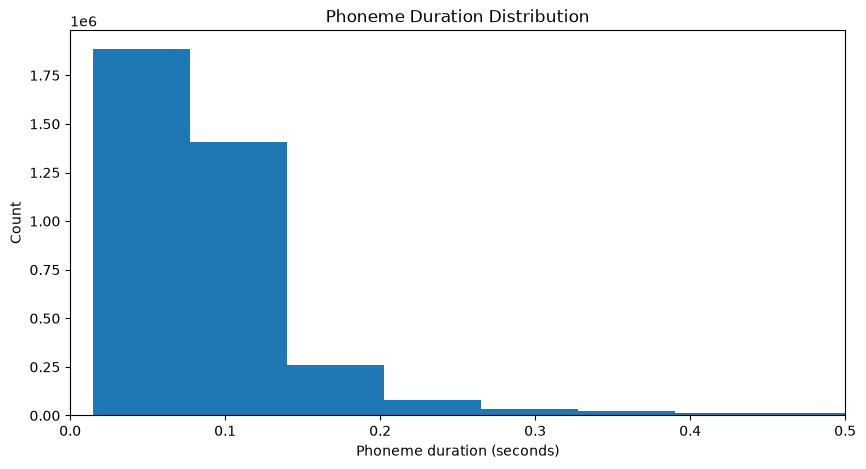

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    phone_durations["duration"],
    bins=100
)

plt.xlabel("Phoneme duration (seconds)")
plt.ylabel("Count")
plt.title("Phoneme Duration Distribution")
plt.xlim(0, 0.5)

plt.show()

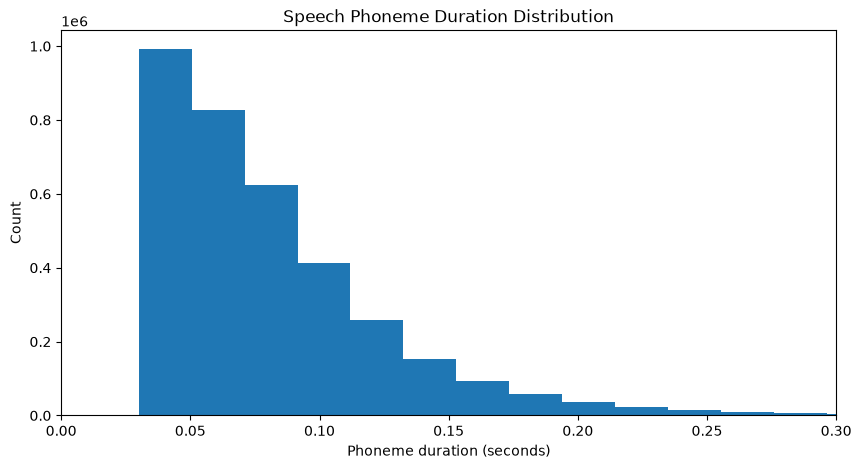

In [31]:
speech_durations = phone_durations[
    ~phone_durations["phone"].isin(["[SIL]", "[UNK]"])
]

plt.figure(figsize=(10, 5))

plt.hist(
    speech_durations["duration"],
    bins=100
)

plt.xlabel("Phoneme duration (seconds)")
plt.ylabel("Count")
plt.title("Speech Phoneme Duration Distribution")
plt.xlim(0, 0.3)

plt.show()

In [32]:
example = dataset_local[0]

print("Text:", example["text"])
print("Duration:", example["duration"])
print("Phones:", example["phones"])

Text: THERE WERE NO FAIRIES AND HOBGOBLINS ABOUT
Duration: 2.75
Phones: ['[SIL]', 'DH', 'EH', 'R', 'W', 'ER', 'N', 'OW', 'F', 'EH', 'R', 'IY', 'Z', 'AH', 'N', 'D', 'HH', 'AA', 'B', 'G', 'AA', 'B', 'L', 'IH', 'N', 'Z', 'AH', 'B', 'AW', 'T', '[SIL]', '[SIL]']


In [33]:
frame_duration = 0.020  # 20 ms

frame_starts = np.arange(
    0,
    example["duration"],
    frame_duration
)

frame_ends = frame_starts + frame_duration

print("Number of frames:", len(frame_starts))
print("First 10 frames:")

for start, end in zip(frame_starts[:10], frame_ends[:10]):
    print(f"{start:.3f} → {end:.3f}")

Number of frames: 138
First 10 frames:
0.000 → 0.020
0.020 → 0.040
0.040 → 0.060
0.060 → 0.080
0.080 → 0.100
0.100 → 0.120
0.120 → 0.140
0.140 → 0.160
0.160 → 0.180
0.180 → 0.200


In [34]:
frame_labels = []

phones = example["phones"]
starts = example["phone_starts"]
ends = example["phone_ends"]

for frame_start, frame_end in zip(frame_starts, frame_ends):

    best_phone = "[UNK]"
    best_overlap = 0.0

    for phone, phone_start, phone_end in zip(
        phones, starts, ends
    ):
        overlap_start = max(frame_start, phone_start)
        overlap_end = min(frame_end, phone_end)

        overlap = max(0.0, overlap_end - overlap_start)

        if overlap > best_overlap:
            best_overlap = overlap
            best_phone = phone

    frame_labels.append(best_phone)

In [35]:
for start, label in zip(frame_starts[:40], frame_labels[:40]):
    print(f"{start:.3f}s → {label}")

0.000s → [SIL]
0.020s → [SIL]
0.040s → [SIL]
0.060s → [SIL]
0.080s → [SIL]
0.100s → [SIL]
0.120s → [SIL]
0.140s → [SIL]
0.160s → [SIL]
0.180s → [SIL]
0.200s → [SIL]
0.220s → [SIL]
0.240s → [SIL]
0.260s → [SIL]
0.280s → [SIL]
0.300s → [SIL]
0.320s → DH
0.340s → DH
0.360s → DH
0.380s → EH
0.400s → R
0.420s → R
0.440s → W
0.460s → W
0.480s → W
0.500s → ER
0.520s → ER
0.540s → ER
0.560s → ER
0.580s → N
0.600s → N
0.620s → N
0.640s → N
0.660s → OW
0.680s → OW
0.700s → OW
0.720s → OW
0.740s → OW
0.760s → F
0.780s → F


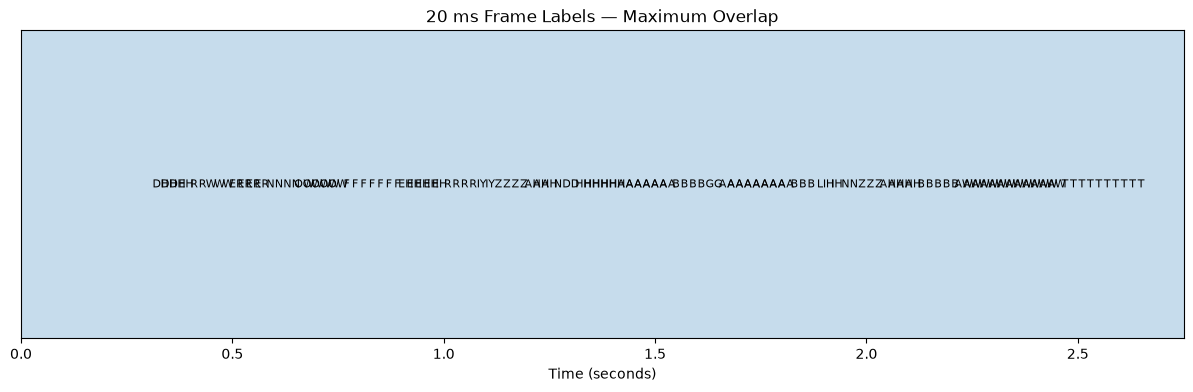

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 4))

for start, end, label in zip(
    frame_starts,
    frame_ends,
    frame_labels
):
    plt.axvspan(
        start,
        end,
        alpha=0.25
    )

    if label != "[SIL]":
        plt.text(
            (start + end) / 2,
            0.5,
            label,
            ha="center",
            va="center",
            fontsize=8
        )

plt.xlim(0, min(example["duration"], 3))
plt.yticks([])
plt.xlabel("Time (seconds)")
plt.title("20 ms Frame Labels — Maximum Overlap")

plt.show()

In [37]:
audio = example["audio"]["array"]
sample_rate = example["audio"]["sampling_rate"]

print("Sample rate:", sample_rate)
print("Samples:", len(audio))
print("Duration:", len(audio) / sample_rate)

Sample rate: 16000
Samples: 44000
Duration: 2.75


In [43]:
import librosa
import numpy as np

n_fft = 400
hop_length = 320
n_mels = 80

mel = librosa.feature.melspectrogram(
    y=audio,
    sr=sample_rate,
    n_fft=n_fft,
    hop_length=hop_length,
    n_mels=n_mels,
    power=2.0
)

log_mel = librosa.power_to_db(
    mel,
    ref=np.max
)

print("Log-Mel shape:", log_mel.shape)

Log-Mel shape: (80, 138)


In [44]:
print("Number of feature frames:", log_mel.shape[1])
print("Number of label frames:", len(frame_labels))

Number of feature frames: 138
Number of label frames: 138


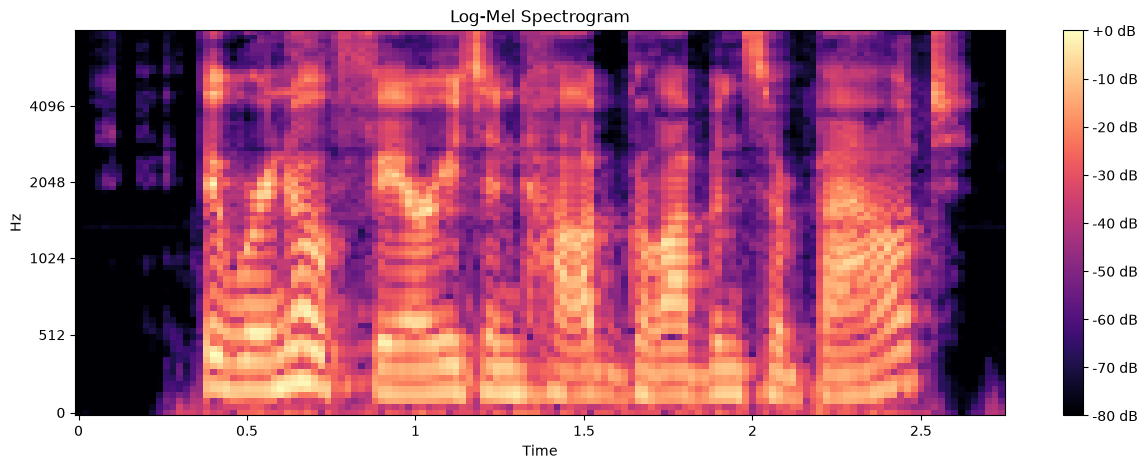

In [45]:
plt.figure(figsize=(15, 5))

librosa.display.specshow(
    log_mel,
    sr=sample_rate,
    hop_length=hop_length,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Log-Mel Spectrogram")
plt.show()

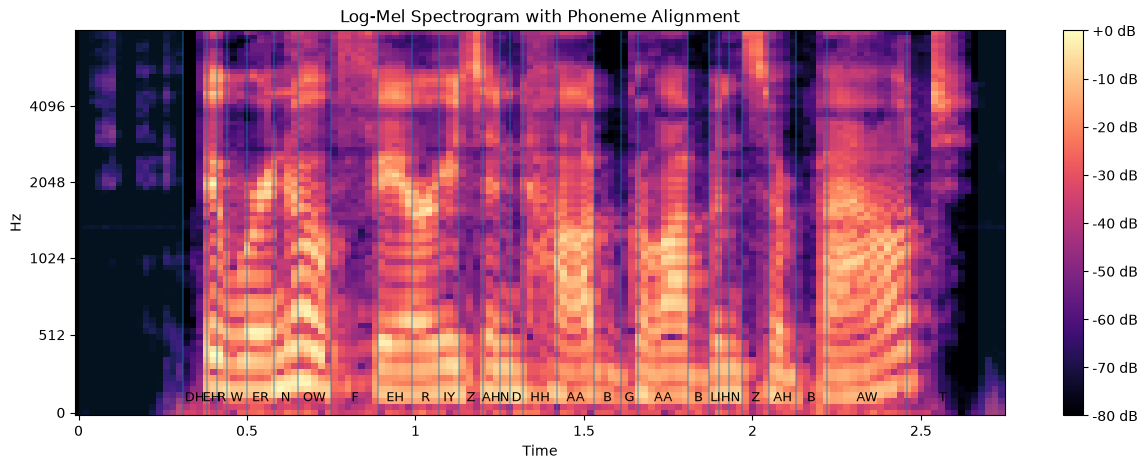

In [46]:
plt.figure(figsize=(15, 5))

librosa.display.specshow(
    log_mel,
    sr=sample_rate,
    hop_length=hop_length,
    x_axis="time",
    y_axis="mel"
)

for phone, start, end in zip(
    example["phones"],
    example["phone_starts"],
    example["phone_ends"]
):
    if phone == "[SIL]":
        plt.axvspan(start, end, alpha=0.15)
    else:
        plt.axvline(start, alpha=0.4)
        plt.text(
            (start + end) / 2,
            75,
            phone,
            ha="center",
            fontsize=9
        )

plt.colorbar(format="%+2.0f dB")
plt.title("Log-Mel Spectrogram with Phoneme Alignment")
plt.show()